In [143]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

data_frame = pd.read_csv("../../data/raw/laboratory_events_codes_2.csv")

In [144]:
mask_val = (data_frame['value'] != "___")
mask_valnum = (data_frame['valuenum'].isna())
data_frame[mask_val & mask_valnum]

,hadm_id,charttime,value,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
171,26913865.0,2189-07-02 10:20:00,NaN,NaN,NaN,NaN,NaN,NaN,EDTA Hold,Blood,EDTA Hold,BATCH_218907_Z1,OK,Normal range: 70-110
193,26913865.0,2189-07-02 10:20:00,NaN,NaN,NaN,NaN,NaN,NaN,Red Top Hold,Blood,Red Top Hold,BATCH_218907_J6,OK,NaN
330,23822395.0,2129-08-06 10:48:00,NOT INTUBATED.,NaN,NaN,NaN,NaN,NaN,Intubated,Blood,Blood Gas,BATCH_212908_B1,OK,NaN
335,23822395.0,2129-08-06 10:48:00,ART.,NaN,NaN,NaN,NaN,NaN,Specimen Type,Blood,Blood Gas,BATCH_212908_H8,OK,Normal range: 70-110
337,23822395.0,2129-08-06 18:54:00,NaN,NaN,NaN,NaN,NaN,NaN,Length of Urine Collection,Urine,Urine Test,BATCH_212908_N2,OK,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
978242,24169669.0,2128-02-25 06:36:00,NaN,NaN,sec,25.0,36.5,NaN,PTT,Blood,Coagulation and Hemostasis,BATCH_212802_P5,OK,NaN
978247,24169669.0,2128-02-25 09:58:00,VEN.,NaN,NaN,NaN,NaN,NaN,Specimen Type,Blood,Blood Gas,BATCH_212802_B5,WARN,Normal range: 3-5
978290,24169669.0,2128-02-26 20:00:00,ART.,NaN,NaN,NaN,NaN,NaN,Specimen Type,Blood,Blood Gas,BATCH_212802_N2,OK,Normal range: 70-110
978347,21557581.0,2145-07-26 16:14:00,NaN,NaN,NaN,NaN,NaN,NaN,Length of Urine Collection,Urine,Urine Test,BATCH_214507_F5,OK,NaN


In [145]:
data_frame=data_frame.drop(columns='value')
data_frame

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,NaN,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,NaN,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,abnormal,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,abnormal,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,abnormal,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,NaN,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,NaN,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,abnormal,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,NaN,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [146]:
grouped = data_frame.groupby('examination_group')['label'].unique()
examination_values_list = grouped.to_dict()
examination_values_list.keys()
grouped

examination_group
ADP                                                                            [ADP]
ANCA Titer                                                              [ANCA Titer]
ARCH-1                                                                      [ARCH-1]
Absolute CD3 Count                                              [Absolute CD3 Count]
Absolute CD4 Count                                              [Absolute CD4 Count]
                                                         ...                        
Urine Test                         [Length of Urine Collection, Urine tube, held,...
Virology                                                [Cytomegalovirus Viral Load]
Vitamin and Nutritional Studies    [Vitamin B12, Ferritin, Folate, Iron, Iron Bin...
Voided Specimen                                                    [Voided Specimen]
proBNP, Pleural                                                    [proBNP, Pleural]
Name: label, Length: 202, dtype: object

Modifico la colonna "flag": i valori NaN diventano 0 e il valore "abnormal" diventa 1

In [147]:
data_frame["flag"] = data_frame["flag"].replace(np.nan, 0)
data_frame["flag"] = data_frame["flag"].replace("abnormal", 1)
data_frame


C:\Users\Cominotti\AppData\Local\Temp\ipykernel_13756\2529097614.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["flag"] = data_frame["flag"].replace("abnormal", 1)


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [148]:
def get_none_percentage_per_cols(data_frame):
    res = []
    cols = du.get_cols(data_frame)
    rows = data_frame.shape[0]
    for col in cols:
        not_none = (data_frame[col].count())
        none_percentage = ((rows - not_none)/rows)*100
        res.append((col, none_percentage))
    return res
# Get the percentage of None values for each columns
none_percentage_per_cols = []

print("PERCENTAGE OF NONE PER COLUMN")
for col, percentage in sorted(get_none_percentage_per_cols(data_frame), key=lambda tup: tup[1], reverse=True):
    print(f"{col}: {percentage:.2f}%")

PERCENTAGE OF NONE PER COLUMN
ref_range: 85.06%
ref_range_lower: 11.54%
ref_range_upper: 11.54%
valueuom: 9.60%
valuenum: 7.27%
hadm_id: 0.00%
charttime: 0.00%
flag: 0.00%
label: 0.00%
fluid: 0.00%
examination_group: 0.00%
analysis_batch_id: 0.00%
qc_flag: 0.00%


In [149]:
# Takes only the heart related examinations
heart_examinations = ['BMP', 'Complete Blood Count (CBC)', 'Cardiac Markers', 'Lipid Panel', 'Coagulation and Hemostasis']
data_frame = data_frame[data_frame['examination_group'].isin(heart_examinations)]
data_frame

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [150]:
# For each (label, examination_group) the number of missing valueuom and percentage of missing valueuom
grouped = data_frame.groupby(['examination_group', 'label'])

#Print the grouped dataframe
print("MISSING VALUEUOM PER (LABEL, EXAMINATION_GROUP)")
for name, group in grouped:
    total = group.shape[0]
    missing_valueuom = group['valueuom'].isna().sum()
    missing_percentage = (missing_valueuom / total) * 100
    print(f"{name}: {missing_valueuom} missing valueuom out of {total} ({missing_percentage:.2f}%)")

#Print ref_range_lower and upper, the valueuom, the label only if label == INR(PT)
inr_data = data_frame[data_frame['label'] == 'INR(PT)'][['ref_range_lower', 'ref_range_upper', 'valueuom', 'label']]
inr_data

MISSING VALUEUOM PER (LABEL, EXAMINATION_GROUP)
('BMP', 'Bicarbonate'): 0 missing valueuom out of 34925 (0.00%)
('BMP', 'Calcium, Total'): 0 missing valueuom out of 29060 (0.00%)
('BMP', 'Chloride'): 0 missing valueuom out of 36612 (0.00%)
('BMP', 'Creatinine'): 0 missing valueuom out of 35939 (0.00%)
('BMP', 'Glucose'): 0 missing valueuom out of 34015 (0.00%)
('BMP', 'Potassium'): 0 missing valueuom out of 37859 (0.00%)
('BMP', 'Sodium'): 0 missing valueuom out of 36712 (0.00%)
('BMP', 'Urea Nitrogen'): 0 missing valueuom out of 35651 (0.00%)
('Cardiac Markers', 'CK-MB Index'): 0 missing valueuom out of 2218 (0.00%)
('Cardiac Markers', 'Creatine Kinase (CK)'): 0 missing valueuom out of 7572 (0.00%)
('Cardiac Markers', 'Creatine Kinase, MB Isoenzyme'): 0 missing valueuom out of 9744 (0.00%)
('Cardiac Markers', 'Lactate Dehydrogenase (LD)'): 0 missing valueuom out of 2745 (0.00%)
('Cardiac Markers', 'NTproBNP'): 0 missing valueuom out of 824 (0.00%)
('Cardiac Markers', 'Troponin T'): 0 

,ref_range_lower,ref_range_upper,valueuom,label
3,0.9,1.1,NaN,INR(PT)
64,0.9,1.1,NaN,INR(PT)
89,0.9,1.1,NaN,INR(PT)
92,0.9,1.1,NaN,INR(PT)
228,0.9,1.1,NaN,INR(PT)
...,...,...,...,...
978183,0.9,1.1,NaN,INR(PT)
978206,0.9,1.1,NaN,INR(PT)
978240,0.9,1.1,NaN,INR(PT)
978243,0.9,1.1,NaN,INR(PT)


In [151]:
# Fill the INR(PT) missing values with "u" 
data_frame.loc[data_frame['label'] == 'INR(PT)', 'valueuom'] = data_frame.loc[data_frame['label'] == 'INR(PT)', 'valueuom'].fillna('u')
data_frame

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,u,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [152]:
# Conta quanti valori distinti di ref_range_lower e ref_range_upper ci sono per ogni label
nunique_check = (
    data_frame
    .groupby('label')[['ref_range_lower', 'ref_range_upper']]
    .nunique(dropna=True)
)

# True se per ogni label entrambi i valori (lower e upper) sono sempre uguali
consistent = (nunique_check <= 1).all(axis=1)

# Etichette incoerenti (range diversi in righe diverse)
inconsistent_labels = consistent[~consistent].index.tolist()

print("Inconsistent labels:", inconsistent_labels)


Inconsistent labels: ['Antithrombin', 'Basophils', 'Calcium, Total', 'Creatine Kinase (CK)', 'Creatinine', 'Eosinophils', 'Factor II', 'Factor VIII', 'Factor X', 'Fibrinogen, Functional', 'Glucose', 'Hematocrit', 'Hemoglobin', 'Lymphocytes', 'Lymphocytes, Percent', 'MCH', 'MCHC', 'Monocytes', 'NTproBNP', 'Neutrophils', 'PT', 'PTT', 'Platelet Count', 'Potassium', 'Protein C, Functional', 'Protein S, Functional', 'Red Blood Cells', 'Sodium', 'Thrombin', 'Von Willebrand Factor Antigen', 'WBC Count', 'White Blood Cells']


In [153]:
# Colonne rilevanti
cols = ["label", "ref_range_lower", "ref_range_upper"]
df_ranges = data_frame[cols].copy()

# Calcola la frequenza di ogni combinazione (label, lower, upper)
range_counts = (
    df_ranges
    .groupby(["label", "ref_range_lower", "ref_range_upper"], dropna=False)
    .size()
    .reset_index(name="count")
)

# Etichette totali nel dataset
all_labels = set(df_ranges["label"].dropna().unique())

# Etichette che hanno almeno un range valido (non tutti NaN)
labels_with_ranges = set(range_counts["label"].dropna().unique())

# Label che non hanno MAI valori di ref_range_lower e upper
labels_no_range = all_labels - labels_with_ranges

# Crea un DataFrame anche per loro (lower/upper NaN, count = 0)
df_no_range = pd.DataFrame({
    "label": list(labels_no_range),
    "ref_range_lower": np.nan,
    "ref_range_upper": np.nan,
    "count": 0
})

range_counts_full = pd.concat([range_counts, df_no_range], ignore_index=True)
range_counts_full = range_counts_full.sort_values(by=["label", "count"], ascending=[True, False]).reset_index(drop=True)

for label, group in range_counts_full.groupby("label"):
    print(f"\n{label}:")
    for _, row in group.iterrows():
        print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")
        


Absolute Basophil Count:
  lower = 0.01, upper = 0.08  →  count = 855

Absolute Eosinophil Count:
  lower = 0.04, upper = 0.54  →  count = 855

Absolute Lymphocyte Count:
  lower = 1.2, upper = 3.7  →  count = 855
  lower = nan, upper = nan  →  count = 11

Absolute Monocyte Count:
  lower = 0.2, upper = 0.8  →  count = 855

Absolute Neutrophil Count:
  lower = 1.6, upper = 6.1  →  count = 855

Antithrombin:
  lower = 80.0, upper = 130.0  →  count = 3
  lower = 69.0, upper = 121.0  →  count = 2

Basophils:
  lower = 0.0, upper = 2.0  →  count = 1970
  lower = 0.0, upper = 1.0  →  count = 855

Bicarbonate:
  lower = 22.0, upper = 32.0  →  count = 34925

CK-MB Index:
  lower = 0.0, upper = 6.0  →  count = 2218

Calcium, Total:
  lower = 8.4, upper = 10.3  →  count = 24617
  lower = 8.4, upper = 10.2  →  count = 4443

Chloride:
  lower = 96.0, upper = 108.0  →  count = 36612

Cholesterol Ratio (Total/HDL):
  lower = nan, upper = nan  →  count = 949

Cholesterol, HDL:
  lower = nan, upper 

In [154]:
#pulire dati secondo questo ordine:
#1 caso: piu coppie numeriche per uno stesso value -> cerchiamo la fonte
#2 caso: una coppia numerica e una coppia NaN -> la coppia NaN diventa coppia numerica
#3 caso: piu coppie numeriche, una/piu coppie NaN -> cerchiamo la fonte + la coppia NaN diventa coppia numerica (soluz caso 1 + soluz caso 2)

#1 caso:
df = range_counts_full.copy()

# Trova le label che NON hanno mai NaN nei range
def has_any_nan(group):
    return group["ref_range_lower"].isna().any() or group["ref_range_upper"].isna().any()

label_has_nan = df.groupby("label").apply(has_any_nan)

# Label che NON hanno mai NaN
labels_no_nan = label_has_nan[~label_has_nan].index

df_no_nan = df[df["label"].isin(labels_no_nan)].copy()

# Conta quante coppie (lower, upper) distinte ci sono per ogni label
numeric_pairs_per_label = (
    df_no_nan
    .groupby("label")
    .apply(lambda g: g[["ref_range_lower", "ref_range_upper"]].drop_duplicates().shape[0])
)

# CASO 1: label con almeno 2 coppie numeriche diverse e MAI NaN
labels_case1 = numeric_pairs_per_label[numeric_pairs_per_label >= 2].index.tolist()

print(f"\n=== CASO 1: LABEL CON ≥ 2 COPPIE NUMERICHE E MAI NaN ===")
for label in labels_case1:
    print(f"\n{label}:")
    group = df_no_nan[df_no_nan["label"] == label]
    for _, row in group.iterrows():
        print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")






=== CASO 1: LABEL CON ≥ 2 COPPIE NUMERICHE E MAI NaN ===

Antithrombin:
  lower = 80.0, upper = 130.0  →  count = 3
  lower = 69.0, upper = 121.0  →  count = 2

Basophils:
  lower = 0.0, upper = 2.0  →  count = 1970
  lower = 0.0, upper = 1.0  →  count = 855

Calcium, Total:
  lower = 8.4, upper = 10.3  →  count = 24617
  lower = 8.4, upper = 10.2  →  count = 4443

Creatine Kinase (CK):
  lower = 47.0, upper = 322.0  →  count = 3155
  lower = 29.0, upper = 201.0  →  count = 1869
  lower = 38.0, upper = 174.0  →  count = 1515
  lower = 26.0, upper = 140.0  →  count = 1033

Creatinine:
  lower = 0.5, upper = 1.2  →  count = 20919
  lower = 0.4, upper = 1.1  →  count = 15020

Eosinophils:
  lower = 0.0, upper = 4.0  →  count = 1970
  lower = 1.0, upper = 7.0  →  count = 855

Factor II:
  lower = 50.0, upper = 150.0  →  count = 1
  lower = 85.0, upper = 145.0  →  count = 1

Factor VIII:
  lower = 50.0, upper = 200.0  →  count = 4
  lower = 50.0, upper = 150.0  →  count = 2

Factor X:
  lo

C:\Users\Cominotti\AppData\Local\Temp\ipykernel_13756\4005999305.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  label_has_nan = df.groupby("label").apply(has_any_nan)
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_13756\4005999305.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g[["ref_range_lower", "ref_range_upper"]].drop_duplicates().shape[0])


In [155]:
df = range_counts_full.copy()

# Separiamo numeriche e NaN
def classify_ranges(group):
    # Coppie numeriche (lower e upper NON NaN)
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    # Coppie completamente NaN
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]
    return numeric, nan_pairs

case2_labels = []

for label, group in df.groupby("label"):
    numeric, nan_pairs = classify_ranges(group)

    # CASO 2:
    # - esattamente UNA coppia numerica
    # - esattamente UNA coppia completamente NaN
    # - nessun'altra combinazione
    if numeric.shape[0] == 1 and nan_pairs.shape[0] == 1:
        case2_labels.append(label)

print("\n=== CASO 2: UNA COPPIA NUMERICA + UNA COPPIA NaN ===")
for label in case2_labels:
    print(f"\n{label}:")
    group = df[df["label"] == label]

    for _, row in group.iterrows():
        is_nan = pd.isna(row["ref_range_lower"]) and pd.isna(row["ref_range_upper"])
        if is_nan:
            print(f"  lower = NaN, upper = NaN  →  count = {int(row['count'])}")
        else:
            print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")



=== CASO 2: UNA COPPIA NUMERICA + UNA COPPIA NaN ===

Absolute Lymphocyte Count:
  lower = 1.2, upper = 3.7  →  count = 855
  lower = NaN, upper = NaN  →  count = 11

Cholesterol, HDL:
  lower = NaN, upper = NaN  →  count = 888
  lower = 41.0, upper = 999.0  →  count = 63

D-Dimer:
  lower = 0.0, upper = 500.0  →  count = 134
  lower = NaN, upper = NaN  →  count = 13


In [156]:
#copy the ref_range_lower and ref_range_upper from case 2 labels where they are NaN
for label in case2_labels:  
    mask_label = data_frame["label"] == label
    # Get the numeric range for this label
    numeric_range = df[(df["label"] == label) & (~df["ref_range_lower"].isna()) & (~df["ref_range_upper"].isna())].iloc[0]
    lower_value = numeric_range["ref_range_lower"]
    upper_value = numeric_range["ref_range_upper"]
    
    # Update the rows where ref_range_lower and ref_range_upper are NaN
    mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()
    data_frame.loc[mask_label & mask_nan, "ref_range_lower"] = lower_value
    data_frame.loc[mask_label & mask_nan, "ref_range_upper"] = upper_value  

data_frame


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,u,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [157]:

df = range_counts_full.copy()

# Prima: calcola caso1 e caso2 così possiamo escluderli
# === CASO 1 ===
labels_case1 = []
for label, group in df.groupby("label"):
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]
    if numeric.shape[0] >= 2 and nan_pairs.shape[0] == 0:
        labels_case1.append(label)

# === CASO 2 ===
labels_case2 = []
for label, group in df.groupby("label"):
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]
    if numeric.shape[0] == 1 and nan_pairs.shape[0] == 1:
        labels_case2.append(label)

# === CASO 3 ===
labels_case3 = []

for label, group in df.groupby("label"):
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]

    # condizioni caso 3
    if (
        numeric.shape[0] >= 2                 # ≥2 coppie numeriche
        and nan_pairs.shape[0] >= 1           # almeno una coppia NaN
        and label not in labels_case1         # non deve essere caso 1
        and label not in labels_case2         # non deve essere caso 2
    ):
        labels_case3.append(label)

# === Stampa risultati ===
print("\n=== CASO 3: ≥2 COPPIE NUMERICHE + ≥1 COPPIA NaN (esclusi caso1, caso2, e singoli numerici) ===")
for label in labels_case3:
    print(f"\n{label}:")
    group = df[df["label"] == label]

    for _, row in group.iterrows():
        if pd.isna(row["ref_range_lower"]) and pd.isna(row["ref_range_upper"]):
            print(f"  lower = NaN, upper = NaN  →  count = {int(row['count'])}")
        else:
            print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")



=== CASO 3: ≥2 COPPIE NUMERICHE + ≥1 COPPIA NaN (esclusi caso1, caso2, e singoli numerici) ===


In [158]:
# Seleziona le righe dove almeno uno dei due valori di riferimento è NaN
nan_refs = data_frame[data_frame['ref_range_lower'].isna() | data_frame['ref_range_upper'].isna()]

# Estrai le label univoche
unique_nan_labels = nan_refs['label'].dropna().unique()
print("Label con valori di riferimento NaN:", unique_nan_labels)

# Seleziona anche le righe del dataframe corrispondenti a queste label
rows_with_nan_labels = data_frame[data_frame['label'].isin(unique_nan_labels)]
rows_with_nan_labels


Label con valori di riferimento NaN: ['Cholesterol Ratio (Total/HDL)' 'Large Platelets' 'Lupus Anticoagulant'
 'Heparin, LMW' 'FMC-7' 'Inhibitor Screen' 'RFXLDLM'
 'HIT-Ab Interpreted Result']


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
12,29654838.0,2188-01-05 06:56:00,3.5,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_218801_C5,OK,NaN
685,28723315.0,2141-08-14 09:30:00,4.3,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_214108_G2,OK,NaN
784,22954658.0,2167-11-10 14:26:00,2.6,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_216711_I7,OK,NaN
933,27658045.0,2146-03-20 01:30:00,1.8,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_214603_G6,OK,NaN
1175,20051301.0,2138-04-27 20:00:00,3.0,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_213804_T9,OK,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
971970,20907483.0,2146-12-03 08:50:00,2.5,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_214612_F5,OK,NaN
972483,23659032.0,2172-03-18 10:01:00,3.7,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_217203_X2,OK,NaN
972750,22709834.0,2163-04-14 09:05:00,5.9,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_216304_B1,OK,NaN
973890,27579698.0,2157-04-15 10:35:00,3.6,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_215704_Y4,OK,NaN


In [159]:
# Nome dell'esame che vuoi selezionare
exam_label = "HIT-Ab Interpreted Result"   # puoi sostituire con quello che ti serve

# Maschera booleana: True solo per le righe con quella label
mask_exam = data_frame["label"] == exam_label

# Applica la maschera al dataframe
selected_exam = data_frame[mask_exam]

print(selected_exam[["label","ref_range_lower","ref_range_upper","valuenum"]])


                            label  ref_range_lower  ref_range_upper  valuenum
602429  HIT-Ab Interpreted Result              NaN              NaN       NaN


In [160]:
#per colesterol Ratio <3.5 https://www.verywellhealth.com/cholesterol-ratio-5189761
# Definisci i range che vuoi usare per tutte le label di colesterolo
cholesterol_lower = 0
cholesterol_upper = 3.5

# Seleziona solo le righe con label che contengono "cholesterol"
mask_chol = data_frame["label"].str.contains("Cholesterol Ratio (Total/HDL)", case=False, na=False)

# Seleziona solo quelle con valori di riferimento mancanti
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Aggiorna i valori di riferimento
data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = cholesterol_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = cholesterol_upper

# Controllo: stampiamo le label aggiornate
print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


C:\Users\Cominotti\AppData\Local\Temp\ipykernel_13756\913598812.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask_chol = data_frame["label"].str.contains("Cholesterol Ratio (Total/HDL)", case=False, na=False)


Empty DataFrame
Columns: [label, ref_range_lower, ref_range_upper]
Index: []


In [161]:
#per Heparin https://pmc.ncbi.nlm.nih.gov/articles/PMC4691677/
# Definisci i range che vuoi usare per tutte le label di heparin
HEPARIN_LMW_lower = 0.2
HEPARIN_LMV_upper = 0.5

# Seleziona solo le righe con label che contengono "cholesterol"
mask_chol = data_frame["label"].str.contains("Heparin, LMW", case=False, na=False)

# Seleziona solo quelle con valori di riferimento mancanti
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Aggiorna i valori di riferimento
data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = HEPARIN_LMW_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = HEPARIN_LMV_upper

# Controllo: stampiamo le label aggiornate
print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


              label  ref_range_lower  ref_range_upper
64026  Heparin, LMW              0.2              0.5


In [162]:
#large Platelet, lupus  FMC7   RFXLDLM   inibitor  HIT-Ab Interpreted Resultrimuoverei
# Lista delle label da eliminare
labels_to_drop = ["Large Platelets", "Lupus Anticoagulant","LMW", "FMC-7", "Inhibitor Screen", "RFXLDLM", "HIT-Ab Interpreted Result"]

# Crea una maschera che esclude quelle label
mask = ~data_frame["label"].isin(labels_to_drop)

# Applica la maschera al dataframe
data_frame = data_frame[mask]

# Controllo: stampiamo le label rimaste
print(data_frame["label"].unique())


['Creatine Kinase (CK)' 'Creatine Kinase, MB Isoenzyme' 'Troponin T'
 'INR(PT)' 'PT' 'PTT' 'Bicarbonate' 'Calcium, Total' 'Chloride'
 'Cholesterol Ratio (Total/HDL)' 'Cholesterol, HDL'
 'Cholesterol, LDL, Calculated' 'Cholesterol, Total' 'Creatinine'
 'Glucose' 'Potassium' 'Sodium' 'Triglycerides' 'Urea Nitrogen'
 'Hematocrit' 'Hemoglobin' 'MCH' 'MCHC' 'MCV' 'Platelet Count' 'RDW'
 'Red Blood Cells' 'White Blood Cells' 'Basophils' 'Eosinophils'
 'Lymphocytes' 'Monocytes' 'Neutrophils' 'CK-MB Index' 'RDW-SD'
 'Cholesterol, LDL, Measured' 'Fibrinogen, Functional' 'NTproBNP'
 'Absolute Lymphocyte Count' 'Absolute Basophil Count'
 'Absolute Eosinophil Count' 'Absolute Monocyte Count'
 'Absolute Neutrophil Count' 'D-Dimer' 'Lactate Dehydrogenase (LD)'
 'Granulocyte Count' 'Fibrin Degradation Products' 'Heparin, LMW'
 'Lymphocytes, Percent' 'WBC Count' 'Protein C, Functional'
 'Protein S, Functional' 'Thrombin' 'Heparin' 'Antithrombin'
 'Protein C, Antigen' 'Protein S, Antigen' 'Factor VIII'

In [163]:
#remove row with 'WARN' or 'FAIL' as 'qc_flag' value, and remove rows with NaN in 'valuenum'
modified = data_frame[~data_frame['qc_flag'].isin(['WARN', 'FAIL'])]
modified = modified.drop('qc_flag', axis=1)
modified = modified.drop('ref_range', axis=1)
modified.dropna(subset=['valuenum'], inplace=True)

#modified.to_csv("../../data/processed/lab_events.csv", index=False)

In [164]:
#IQR di label
label_count = data_frame['label'].value_counts()

# Calcola Q1, Q3 e IQR
q1 = label_count.quantile(0.25)
q3 = label_count.quantile(0.75)
iqr = q3 - q1

# Calcola i limiti
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print(f"Q1 (25%): {q1}")
print(f"Q3 (75%): {q3}")
print(f"IQR: {iqr}")
print(f"Lower limit: {lower_limit}")
print(f"Upper limit: {upper_limit}")

# Identifica gli label da rimuovere (sotto il limite inferiore)
rare_label_count_iqr = label_count[label_count < lower_limit].index

print(f"\n Label  da rimuovere (sotto il limite): {len(rare_label_count_iqr)}")
print(rare_label_count_iqr.tolist())

# Rimuove label rare
modified = modified[~modified['label'].isin(rare_label_count_iqr)]

print(f"\nShape dopo rimozione: {data_frame.shape}")
print(f"label  rimasti: {modified['label'].nunique()}")
label_count_after = modified['label'].value_counts()
label_count_after

Q1 (25%): 13.0
Q3 (75%): 27059.5
IQR: 27046.5
Lower limit: -40556.75
Upper limit: 67629.25

 Label  da rimuovere (sotto il limite): 0
[]

Shape dopo rimozione: (667009, 13)
label  rimasti: 63


label
Potassium             34047
Chloride              33055
Sodium                32917
Creatinine            32334
Urea Nitrogen         32070
                      ...  
Factor X                  2
Protein C, Antigen        1
Eosinophil Count          1
Factor V                  1
Factor VII                1
Name: count, Length: 63, dtype: int64

In [165]:
#Mask to find all the rows where 'valuenum' it outside the upper-lower range
mask_1 = (modified['valuenum'] < modified['ref_range_lower']) | (modified['valuenum'] > modified['ref_range_upper'])

# Mask to find all the rows where the flag is set to 0 (not abnormal)
mask_2 = (modified['flag'] == 0)

#if mask 1 and mask 2 are true , chaange the flag to 1 (abnormal)
modified.loc[mask_1 & mask_2, 'flag'] = 1





In [166]:
#Mask to find all the rows where 'valuenum' is inside  the upper-lower range
mask_1 = (modified['valuenum'] >= modified['ref_range_lower']) & (modified['valuenum'] <= modified['ref_range_upper'])
 
# Mask to find all the rows where the flag is set to 0 (not abnormal)
mask_2 = (modified['flag'] == 1)

#if mask 1 and mask 2 are true , chaange the flag to 1 (abnormal)
modified.loc[mask_1 & mask_2, 'flag'] = 0
modified

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4
3,29654838.0,2188-01-05 06:56:00,1.20,u,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7
5,29654838.0,2188-01-05 06:56:00,85.80,sec,25.0,36.50,1,PTT,Blood,Coagulation and Hemostasis,BATCH_218801_R1
...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6


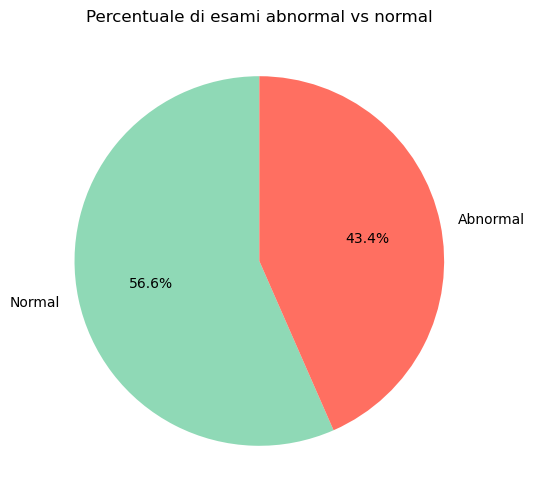

In [167]:
counts = modified['flag'].value_counts()

# Grafico a torta
plt.figure(figsize=(6,6))
plt.pie(
    counts,
    labels=['Normal', 'Abnormal'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#8fd9b6','#ff6f61']
)
plt.title("Percentuale di esami abnormal vs normal")
plt.show()

In [168]:
print(data_frame['label'].nunique())   

66


In [169]:
# Raggruppa per esame e calcola min e max
# Calcola min e max osservati per ogni esame
exam_min_max = (
    modified.groupby('label')['valuenum']
    .agg(['min', 'max'])
    .reset_index()
)

# Prendi i valori di riferimento (assumendo che siano già nel dataframe)
ref_ranges = (
   modified[['label', 'ref_range_lower', 'ref_range_upper','valueuom']]
    .drop_duplicates('label')   # evita duplicati per ogni eesame
)

# Unisci le due tabelle
exam_min_max = exam_min_max.merge(ref_ranges, on='label', how='left')

print(exam_min_max)


                             label    min      max  ref_range_lower  \
0          Absolute Basophil Count   0.00     0.66             0.01   
1        Absolute Eosinophil Count   0.00     1.50             0.04   
2        Absolute Lymphocyte Count   0.00  3825.00             1.20   
3          Absolute Monocyte Count   0.00     3.11             0.20   
4        Absolute Neutrophil Count   0.32    41.66             1.60   
..                             ...    ...      ...              ...   
58                   Urea Nitrogen   3.00   207.00             6.00   
59  Von Willebrand Factor Activity  55.00   271.00            50.00   
60   Von Willebrand Factor Antigen  60.00   190.00            60.00   
61                       WBC Count   2.00    12.40             4.00   
62               White Blood Cells   0.40   234.90             4.00   

    ref_range_upper valueuom  
0              0.08     K/uL  
1              0.54     K/uL  
2              3.70     K/uL  
3              0.80    

In [ ]:
# Sostituisci i valori oltre la soglia massima con il doppio della sgolia stessa, e sotto al soglio minima con la metà
modified['valuenum'] = np.where(
    modified['valuenum'] < modified['ref_range_lower']/3,
    modified['ref_range_lower'] / 3,   # capping verso il basso
    np.where(
        modified['valuenum'] > modified['ref_range_upper']*3,
        modified['ref_range_upper'] * 3,   # capping verso l’alto
        modified['valuenum']               # valori già plausibili
    )
)

In [171]:
# Raggruppa per esame e calcola min e max
# Calcola min e max osservati per ogni esame
exam_min_max = (
    modified.groupby('label')['valuenum']
    .agg(['min', 'max'])
    .reset_index()
)

# Prendi i valori di riferimento (assumendo che siano già nel dataframe)
ref_ranges = (
   modified[['label', 'ref_range_lower', 'ref_range_upper','valueuom']]
    .drop_duplicates('label')   # evita duplicati per ogni eesame
)

# Unisci le due tabelle
exam_min_max = exam_min_max.merge(ref_ranges, on='label', how='left')

print(exam_min_max)



                             label     min     max  ref_range_lower  \
0          Absolute Basophil Count   0.005    0.16             0.01   
1        Absolute Eosinophil Count   0.020    1.08             0.04   
2        Absolute Lymphocyte Count   0.600    7.40             1.20   
3          Absolute Monocyte Count   0.100    1.60             0.20   
4        Absolute Neutrophil Count   0.800   12.20             1.60   
..                             ...     ...     ...              ...   
58                   Urea Nitrogen   3.000   40.00             6.00   
59  Von Willebrand Factor Activity  55.000  271.00            50.00   
60   Von Willebrand Factor Antigen  60.000  190.00            60.00   
61                       WBC Count   2.000   12.40             4.00   
62               White Blood Cells   2.000   22.00             4.00   

    ref_range_upper valueuom  
0              0.08     K/uL  
1              0.54     K/uL  
2              3.70     K/uL  
3              0.80    

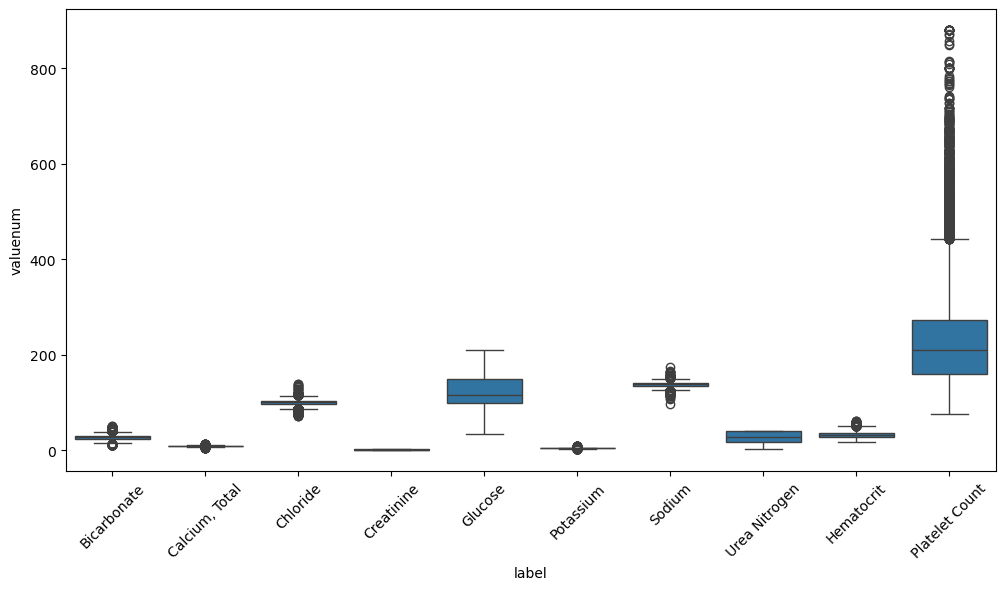

In [172]:
# Filtra solo gli esami sul fluido sangue


# Conta quante osservazioni per ogni esame
counts = modified['label'].value_counts().head(10).index

# Filtra solo i top 10 esami
subset = modified[modified['label'].isin(counts)]

plt.figure(figsize=(12,6))
sns.boxplot(x='label', y='valuenum', data=subset)
plt.xticks(rotation=45)
plt.show()
modified.drop(['ref_range_lower', 'ref_range_upper'], axis=1, inplace=True)
modified.to_csv("../../data/processed/lab_events.csv", index=False)